# 04 — River basins of New England

Every river segment in the six New England states, colored by the river basin it drains to (14 HydroBASINS units at Pfafstetter level 5) and sized by Strahler stream order.

Data: [HydroSHEDS](https://www.hydrosheds.org/) (HydroBASINS v1c and HydroRIVERS v1.0) and the US Census Bureau. Made for the [#30DayMapChallenge](https://30daymapchallenge.com/) 2026, day 3: Polygons.

## 1. Imports and fonts 



In [1]:
import geopandas as gpd
from matplotlib.colors import ListedColormap
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_manager.fontManager.addfont(
    "Fonts/Montserrat-Bold.ttf"
)
font_manager.fontManager.addfont(
    "Fonts/Montserrat-Light.ttf"
)

## 2.  Settings 

In [2]:
# New England bounding box: degrees, minutes, seconds -> decimal degrees (west longitudes are negative)
west_newE = -(73 + 43/60 + 39/3600)
east_newE = -(66 + 56/60 + 59/3600) 
south_newE = (40 + 59/60 + 0/3600)
north_newE = (47 + 27/60 + 35/3600)

ne_box = (west_newE, south_newE, east_newE, north_newE)


basins_path = "data/hybas_na_lev01-12_v1c/hybas_na_lev12_v1c.shp"  # path to the level-12 basins (the bridge to the rivers)
rivers_path = "../03-rivers/data/HydroRIVERS_v10_na_shp"  # rivers reused from map 03
states_path = "../03-rivers/data/cb_2025_us_state_5m"
basins_path_lv5 = "data/hybas_na_lev01-12_v1c/hybas_na_lev05_v1c.shp"

# a palette of colors for the basins
my_colors = ['#fba097', "#f8b287", '#ece7ac', '#c6efbf', '#c4dbf7', "#9766fa", "#f599c2","#edce87",  "#f67d7d", "#caf973", "#3bfbcb", "#4dc57b", "#f97603", "#2253f5"]
my_cmap = ListedColormap(my_colors)
background_color = "#1a1a1a"   
font_family = "Montserrat"
dim_color = "#585757"
land_color = "#2b2b3a"

## 3. Helper functions 



In [3]:
# The export helpers are shared by all the maps, so they live in ../plate_canvas.py
import sys
sys.path.append("..")  # the shared canvas lives one folder up, in plate_canvas.py
from plate_canvas import new_plate, finish_plate

## 4. Load data

In [4]:
basins = gpd.read_file(basins_path, bbox=ne_box)
rivers = gpd.read_file(rivers_path, bbox=ne_box)
state = gpd.read_file(states_path)
basins_lv5 = gpd.read_file(basins_path_lv5)


## 5. Join and clip

In [5]:
merged = pd.merge(rivers, basins[["HYBAS_ID", "PFAF_ID"]], left_on="HYBAS_L12", right_on="HYBAS_ID",how="left")
ne_states = state[state["STUSPS"].isin(["MA","RI","NH","ME","CT","VT"])]
ne_states = ne_states.to_crs(basins.crs) 
ne_rivers_basins = gpd.clip(merged, ne_states)
ne_basins_lv5 = gpd.clip(basins_lv5, ne_states)


## 6. Choose basins

In [6]:
ne_rivers_basins["PFAF_ID"] = ne_rivers_basins["PFAF_ID"].astype("string")
ne_rivers_basins["PFAF_L5"] = ne_rivers_basins["PFAF_ID"].str[:5]
ne_basins_lv5["PFAF_ID"] = ne_basins_lv5["PFAF_ID"].astype("string")
missing_basins = ne_basins_lv5[~ne_basins_lv5["PFAF_ID"].isin(ne_rivers_basins["PFAF_L5"])]
ne_basins_lv5_final = ne_basins_lv5[ne_basins_lv5["PFAF_ID"].isin(ne_rivers_basins["PFAF_L5"])]


## 7. Check 

In [7]:
print(ne_rivers_basins.columns.tolist())
print(len(merged))                             # expected: 24339 (all rivers in the box, before the clip)
print(merged["PFAF_ID"].isna().sum())           # expected: 0 (every river found its basin)
print(len(ne_rivers_basins))                    # expected: 15819 (after the clip)
print(ne_rivers_basins["PFAF_L5"].nunique())    # expected: 14 level-5 basins with rivers
print(missing_basins["PFAF_ID"].tolist())       # expected: ['72510'] (a sliver in Canada, no rivers)
print(merged.columns.tolist())

['HYRIV_ID', 'NEXT_DOWN', 'MAIN_RIV', 'LENGTH_KM', 'DIST_DN_KM', 'DIST_UP_KM', 'CATCH_SKM', 'UPLAND_SKM', 'ENDORHEIC', 'DIS_AV_CMS', 'ORD_STRA', 'ORD_CLAS', 'ORD_FLOW', 'HYBAS_L12', 'geometry', 'HYBAS_ID', 'PFAF_ID', 'PFAF_L5']
24339
0
15819
14
['72510']
['HYRIV_ID', 'NEXT_DOWN', 'MAIN_RIV', 'LENGTH_KM', 'DIST_DN_KM', 'DIST_UP_KM', 'CATCH_SKM', 'UPLAND_SKM', 'ENDORHEIC', 'DIS_AV_CMS', 'ORD_STRA', 'ORD_CLAS', 'ORD_FLOW', 'HYBAS_L12', 'geometry', 'HYBAS_ID', 'PFAF_ID']


## 8. Plot

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

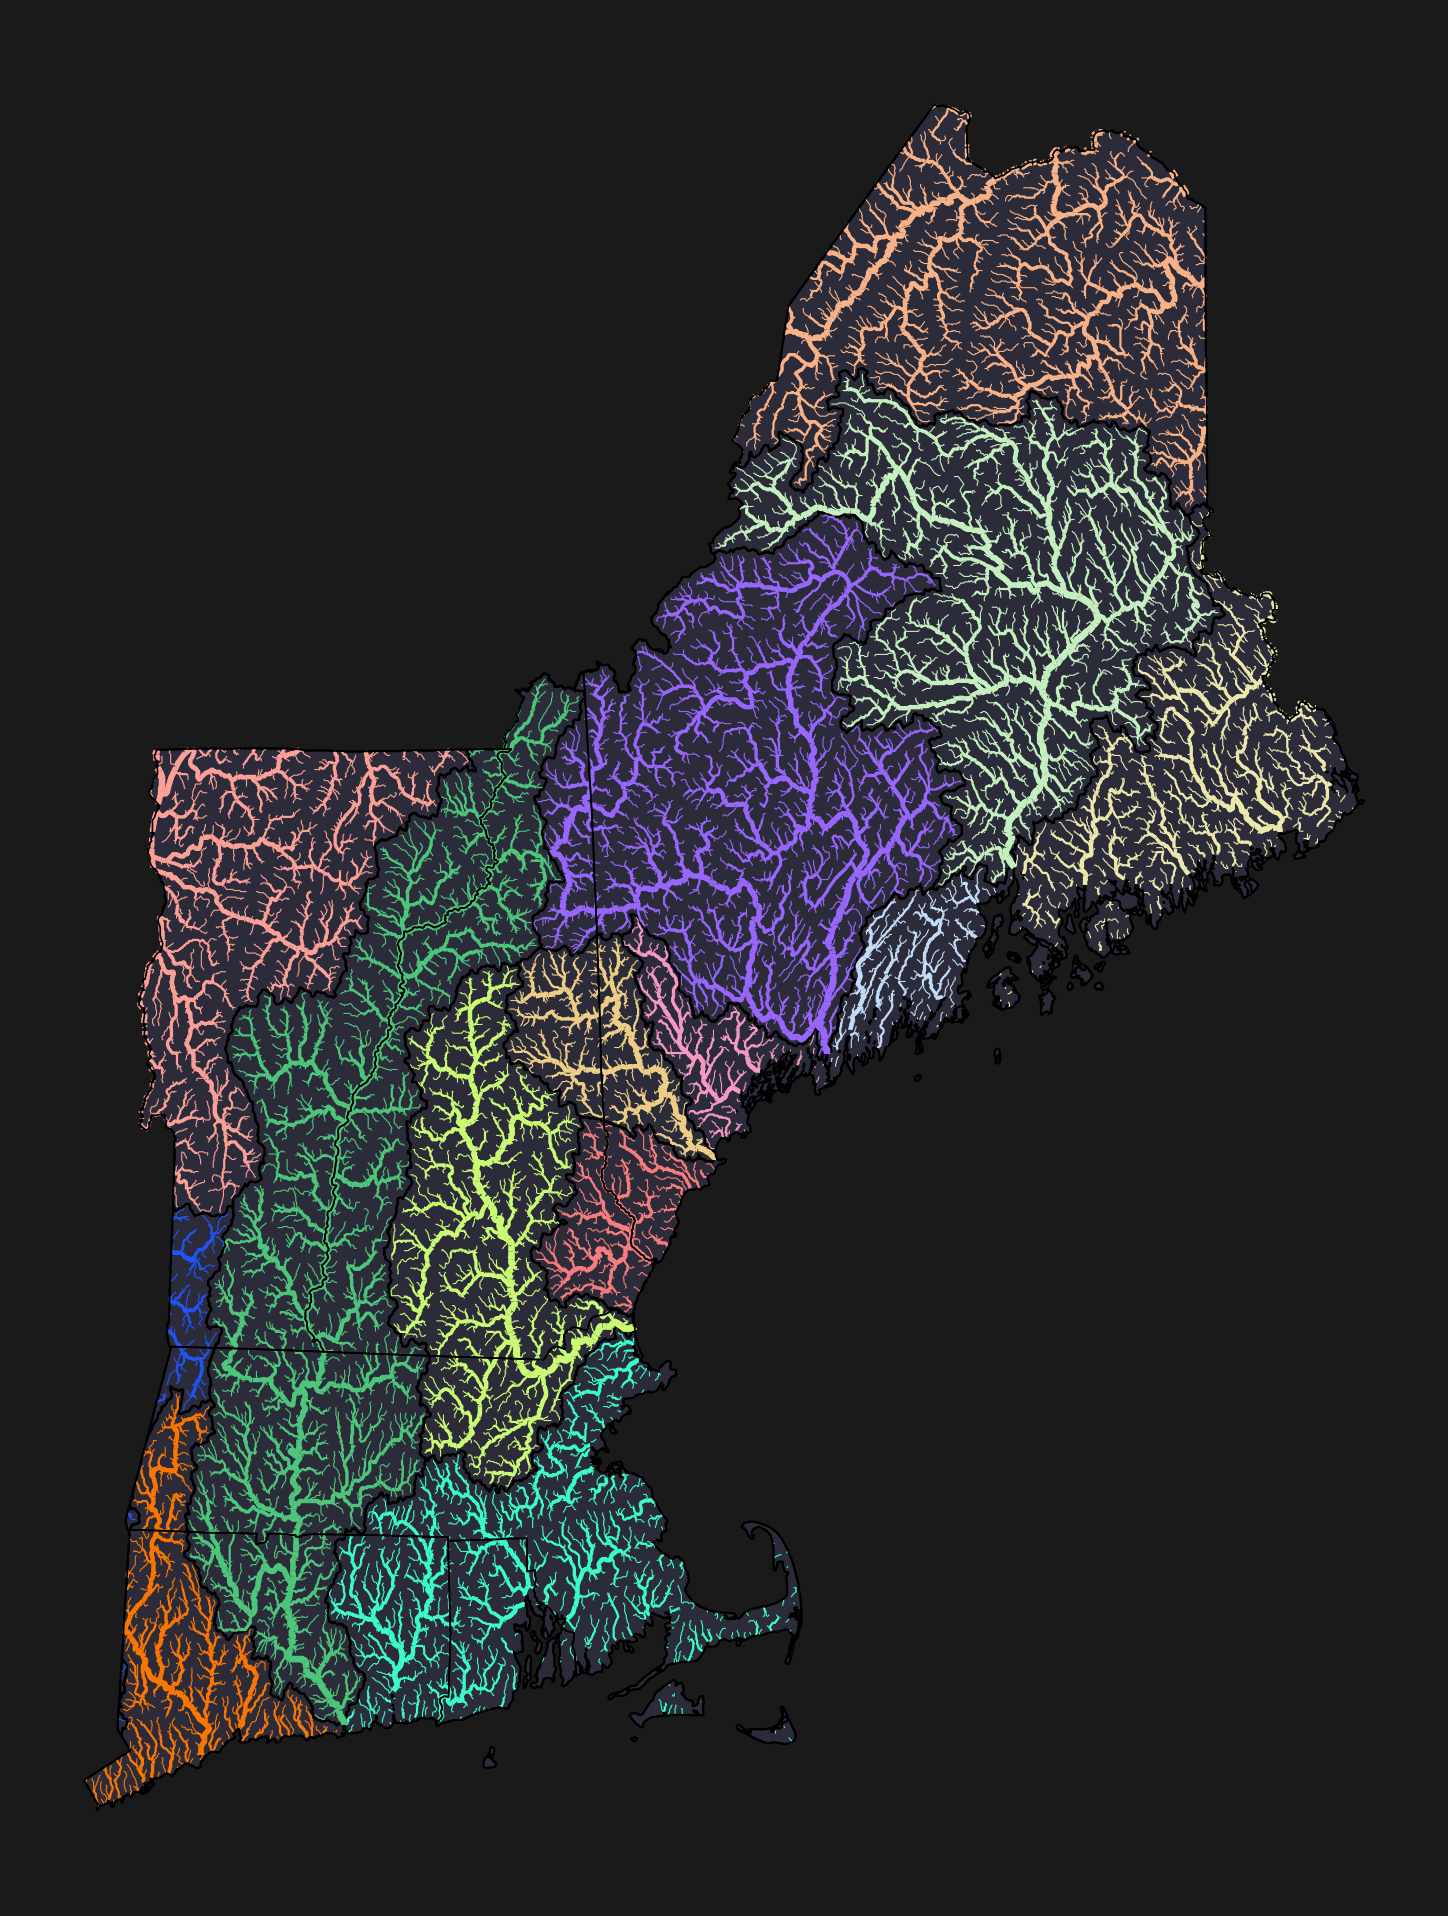

In [8]:
fig, ax = new_plate()  # same figure size and map box as every other plate

ne_states.plot(color=land_color, linewidth=0.3, ax=ax)
ne_basins_lv5_final.boundary.plot(color="black", linewidth=0.8, ax=ax)
ne_rivers_basins.plot(column="PFAF_L5", cmap=my_cmap, linewidth=ne_rivers_basins["ORD_STRA"]*0.4, categorical=True, ax=ax)
ne_states.boundary.plot(color="black", linewidth=0.6, ax=ax)

In [9]:
# The title, the credits, the map area and the save are the same on every plate,
# so they come from plate_canvas.py. The export is always 1900 x 2040 px.
finish_plate(
    fig, ax,
    kicker="River basins",
    title="NEW ENGLAND",
    note="14 river basins · coloured by Pfafstetter level 5",
    credit="Data: HydroSHEDS – HydroBASINS v1c & HydroRIVERS v1.0 (Lehner & Grill 2013) · US Census Bureau\nStyle inspired by Milos Popovic",
    path="ne_basins.png",
    title_color="lightyellow",
)

findfont: Failed to find font weight light for Montserrat, now using 300.


findfont: Failed to find font weight light for Montserrat, now using 300.


findfont: Failed to find font weight light for Montserrat, now using 300.


saved ne_basins.png (1900, 2040)


'ne_basins.png'